# TP 3 Boolean Retrieval Inverted Index

by ```HEAM Visal``` ID:```e20221349```

## Problem 1. Create a Term-Document Incidence Matrix

### Task: Create a binary Term-Document Inidence Matrix of a small set of documents

### Instructions: 

#### 1. Choose the following six sample documents (docIDs 1 to 6):

- Document 1: "Data science combines statistics, computer science, and domain knowledge."
-  Document 2: "Machine learning algorithms can analyze large datasets and make predictions."
- Document 3: "Data visualization helps in interpreting complex data and communicating insights."
- Document 4: "Computer science students learn machine learning and data mining."
- Document 5: "Search engines use an inverted index to retrieve documents for a query."
- Document 6: "Statistics and machine learning help data scientists build predictive models."


In [30]:
Docs = [
    "Data science combines statistics, computer science, and domain knowledge.",
    "Machine learning algorithms can analyze large datasets and make predictions.",
    "Data visualization helps in interpreting complex data and communicating insights.",
    "Computer science students learn machine learning and data mining.",
    "Search engines use an inverted index to retrieve documents for a query.",
    "Statistics and machine learning help data scientists build predictive models."
]

#### 2. Write a function to tokenize each document (convert to lowercase, split into words, remove punctuation) and build the sorted vocabulary.

In [31]:
import re
def tokenize(doc):
    return re.findall(r'[a-z]+', doc.lower())

# token the docs
Docs_Tokenized = [tokenize(doc) for doc in Docs]

# remove duplicates 
Word_set = {word for doc in Docs_Tokenized for word in doc}

vocabs = sorted(Word_set)

print(vocabs[0:7])
print("Number of different Word: %d" % (len(vocabs)))

['a', 'algorithms', 'an', 'analyze', 'and', 'build', 'can']
Number of different Word: 44


#### 3. Construct the incidence matrix: rows represent terms, columns represent documents, and an entry is 1 if the term occurs in the document, 0 otherwise. Print it with labels for terms and documents.

In [32]:
import pandas as pd
Matrix = []
clmn = ["Doc1", "Doc2", "Doc3", "Doc4", "Doc5", "Doc6"]

for term in vocabs :
    row = []
    for words in Docs_Tokenized:
        if term in words :
            row.append(1)
        else :
            row.append(0)
    Matrix.append(row)
table = pd.DataFrame(Matrix, index=vocabs, columns=clmn)
table

,Doc1,Doc2,Doc3,Doc4,Doc5,Doc6
a,0,0,0,0,1,0
algorithms,0,1,0,0,0,0
an,0,0,0,0,1,0
analyze,0,1,0,0,0,0
and,1,1,1,1,0,1
build,0,0,0,0,0,1
can,0,1,0,0,0,0
combines,1,0,0,0,0,0
communicating,0,0,1,0,0,0
complex,0,0,1,0,0,0


#### 4. Answer the query ```data``` AND ```science``` AND NOT ```machine``` with bitwise operations on the rows of the matrix: take the complement of the row of machine, then AND the three vectors (Lecture 3: Brutus AND Caesar AND NOT Calpurnia). Print the vectors and the matching documents.

In [33]:
data_row = table.loc["data", :]
science_row = table.loc["science", :]
machine_row = table.loc["machine", :]

# find not machine
not_machine = 1 - machine_row

# query "data AND science AND NOT machine"
result = data_row & science_row & not_machine

tableSearch = pd.DataFrame([data_row, science_row, machine_row, not_machine, result],
                           index=["data", "science", "machine", "not machine", "Result"])
print(tableSearch)

matching_docs_id = []
for doc_id, match in enumerate(result, start=1):
    if match == 1:
        matching_docs_id.append(doc_id)

print("\nMatching documents-N.o:", matching_docs_id)
print("Matching documents :", " ".join(Docs_Tokenized[matching_docs_id[0]-1]))
# "x".join is to combine string by add "x" between 

             Doc1  Doc2  Doc3  Doc4  Doc5  Doc6
data            1     0     1     1     0     1
science         1     0     0     1     0     0
machine         0     1     0     1     0     1
not machine     1     0     1     0     1     0
Result          1     0     0     0     0     0

Matching documents-N.o: [1]
Matching documents : data science combines statistics computer science and domain knowledge


## Problem 2: Build an Inverted Index

### Task: Build the inverted index of the collection by sorting (term, docID) pairs.

### Instructions:
#### 1. Using the tokenizer from Problem 1, generate the sequence of (term, docID) pairs for all documents, in document order.



In [34]:
pairs = []
for docID, words in enumerate(Docs_Tokenized, start=1):
    for word in words:
        pairs.append([word, docID])

print("Before sort: ", pairs)



Before sort:  [['data', 1], ['science', 1], ['combines', 1], ['statistics', 1], ['computer', 1], ['science', 1], ['and', 1], ['domain', 1], ['knowledge', 1], ['machine', 2], ['learning', 2], ['algorithms', 2], ['can', 2], ['analyze', 2], ['large', 2], ['datasets', 2], ['and', 2], ['make', 2], ['predictions', 2], ['data', 3], ['visualization', 3], ['helps', 3], ['in', 3], ['interpreting', 3], ['complex', 3], ['data', 3], ['and', 3], ['communicating', 3], ['insights', 3], ['computer', 4], ['science', 4], ['students', 4], ['learn', 4], ['machine', 4], ['learning', 4], ['and', 4], ['data', 4], ['mining', 4], ['search', 5], ['engines', 5], ['use', 5], ['an', 5], ['inverted', 5], ['index', 5], ['to', 5], ['retrieve', 5], ['documents', 5], ['for', 5], ['a', 5], ['query', 5], ['statistics', 6], ['and', 6], ['machine', 6], ['learning', 6], ['help', 6], ['data', 6], ['scientists', 6], ['build', 6], ['predictive', 6], ['models', 6]]


#### 2. Sort the pairs by term, then by docID.

In [35]:
sorted_pairs = sorted(pairs)

print("After sort by term: ", sorted_pairs)

After sort by term:  [['a', 5], ['algorithms', 2], ['an', 5], ['analyze', 2], ['and', 1], ['and', 2], ['and', 3], ['and', 4], ['and', 6], ['build', 6], ['can', 2], ['combines', 1], ['communicating', 3], ['complex', 3], ['computer', 1], ['computer', 4], ['data', 1], ['data', 3], ['data', 3], ['data', 4], ['data', 6], ['datasets', 2], ['documents', 5], ['domain', 1], ['engines', 5], ['for', 5], ['help', 6], ['helps', 3], ['in', 3], ['index', 5], ['insights', 3], ['interpreting', 3], ['inverted', 5], ['knowledge', 1], ['large', 2], ['learn', 4], ['learning', 2], ['learning', 4], ['learning', 6], ['machine', 2], ['machine', 4], ['machine', 6], ['make', 2], ['mining', 4], ['models', 6], ['predictions', 2], ['predictive', 6], ['query', 5], ['retrieve', 5], ['science', 1], ['science', 1], ['science', 4], ['scientists', 6], ['search', 5], ['statistics', 1], ['statistics', 6], ['students', 4], ['to', 5], ['use', 5], ['visualization', 3]]


#### 3. Merge multiple entries of the same term in the same document, then group the pairs into a dictionary: term → (document frequency, postings list). Each postings list must be sorted by docID.

In [36]:
# find it's posting
postings = {}
for term, doc_id in sorted_pairs :
    if term not in postings :
        postings[term] = []
    if doc_id not in postings[term] :
        postings[term].append(doc_id)

postings

{'a': [5],
 'algorithms': [2],
 'an': [5],
 'analyze': [2],
 'and': [1, 2, 3, 4, 6],
 'build': [6],
 'can': [2],
 'combines': [1],
 'communicating': [3],
 'complex': [3],
 'computer': [1, 4],
 'data': [1, 3, 4, 6],
 'datasets': [2],
 'documents': [5],
 'domain': [1],
 'engines': [5],
 'for': [5],
 'help': [6],
 'helps': [3],
 'in': [3],
 'index': [5],
 'insights': [3],
 'interpreting': [3],
 'inverted': [5],
 'knowledge': [1],
 'large': [2],
 'learn': [4],
 'learning': [2, 4, 6],
 'machine': [2, 4, 6],
 'make': [2],
 'mining': [4],
 'models': [6],
 'predictions': [2],
 'predictive': [6],
 'query': [5],
 'retrieve': [5],
 'science': [1, 4],
 'scientists': [6],
 'search': [5],
 'statistics': [1, 6],
 'students': [4],
 'to': [5],
 'use': [5],
 'visualization': [3]}

In [37]:
# make dict term : (count, posting)
index = {}
for term, doc_ids in postings.items():
    index[term] = (len(doc_ids), doc_ids)
index

{'a': (1, [5]),
 'algorithms': (1, [2]),
 'an': (1, [5]),
 'analyze': (1, [2]),
 'and': (5, [1, 2, 3, 4, 6]),
 'build': (1, [6]),
 'can': (1, [2]),
 'combines': (1, [1]),
 'communicating': (1, [3]),
 'complex': (1, [3]),
 'computer': (2, [1, 4]),
 'data': (4, [1, 3, 4, 6]),
 'datasets': (1, [2]),
 'documents': (1, [5]),
 'domain': (1, [1]),
 'engines': (1, [5]),
 'for': (1, [5]),
 'help': (1, [6]),
 'helps': (1, [3]),
 'in': (1, [3]),
 'index': (1, [5]),
 'insights': (1, [3]),
 'interpreting': (1, [3]),
 'inverted': (1, [5]),
 'knowledge': (1, [1]),
 'large': (1, [2]),
 'learn': (1, [4]),
 'learning': (3, [2, 4, 6]),
 'machine': (3, [2, 4, 6]),
 'make': (1, [2]),
 'mining': (1, [4]),
 'models': (1, [6]),
 'predictions': (1, [2]),
 'predictive': (1, [6]),
 'query': (1, [5]),
 'retrieve': (1, [5]),
 'science': (2, [1, 4]),
 'scientists': (1, [6]),
 'search': (1, [5]),
 'statistics': (2, [1, 6]),
 'students': (1, [4]),
 'to': (1, [5]),
 'use': (1, [5]),
 'visualization': (1, [3])}

#### 4. Print the document frequency and the postings list of: data, science, machine, learning, statistics, computer.


In [38]:
target = ["data", "science", "machine", "learning", "statistics", "computer"]

for i in target:
    df, docs = index[i]
    print(i, "-> count:", df, "| documents:", docs)

data -> count: 4 | documents: [1, 3, 4, 6]
science -> count: 2 | documents: [1, 4]
machine -> count: 3 | documents: [2, 4, 6]
learning -> count: 3 | documents: [2, 4, 6]
statistics -> count: 2 | documents: [1, 6]
computer -> count: 2 | documents: [1, 4]


#### 5. Compare the number of cells of the incidence matrix with the number of postings in the index. Which representation would you use for a collection of 1 million documents, and why?

In [39]:
matrix_cells = len(vocabs) * len(Docs)

total_postings = 0
for df, doc_ids in index.values():
    total_postings += len(doc_ids)

print("Matrix cells:", matrix_cells)
print("Total postings:", total_postings)

Matrix cells: 264
Total postings: 58


##### Answer: 

I would use an inverted index. Most words appear in only a small part of the collection, so the matrix would contain many zeros. The inverted index stores only the document IDs where each word appears. This usually saves space and lets us find matching documents quickly.


## Problem 3: Implement the Merge Algorithm

### Task: Process Boolean queries by merging the postings lists of the inverted index.

### Instructions:

#### 1. Using the index from Problem 2, implement the INTERSECT algorithm of Lecture 3, which walks through the two sorted postings lists simultaneously in O(x + y) time:

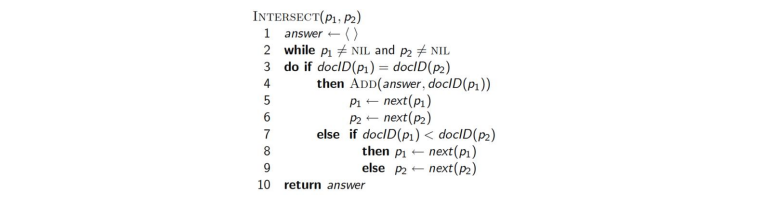



In [40]:
def intersect(p1, p2):
    answer = []
    i, j = 0, 0 
    while i < len(p1) and j < len(p2):
        if p1[i] == p2[j] :
            answer.append(p1[i])
            i += 1
            j += 1
        elif p1[i] > p2[j]:
            j += 1
        else :
            i += 1
    return answer

#### 2. Write two more functions for x OR y and x AND NOT y, also as linear merges of the two sorted lists (do not use Python sets).


In [41]:
def union(p1, p2):
    answer = []
    i, j = 0, 0
    while i < len(p1) and j < len(p2):
        if p1[i] == p2[j]:
            answer.append(p1[i])
            i += 1
            j += 1
        elif p1[i] < p2[j]:
            answer.append(p1[i])
            i += 1
        else :
            answer.append(p2[j])
            j += 1
    # Keep any IDs left in either list
    result.extend(p2[i:])
    result.extend(p2[j:])
    return answer

def different(p1, p2):
    answer = []
    i, j = 0, 0
    while i < len(p1) and j < len(p2):
        if p1[i] == p2[j] :
            i += 1
            j += 1
        elif p1[i] < p2[j]:
            # Not in list2(p2): keep it
            answer.append(p1[i])
            i += 1
        else:
            j += 1
    # Once list2 ends, keep anything left in list1
    result.extend(p1[i:])
    
    

#### 3. Process the following queries and print the results:
- Query 1: data AND machine
- Query 2: statistics OR learning
- Query 3: data AND NOT science

In [42]:
# Query 1: data AND machine
q1 = intersect(index["data"][1], index["machine"][1])

# Query 2: statistics OR learning
q2 = union(index["statistics"][1], index["learning"][1])

# Query 3: data AND NOT science
q3 = difference(index["data"][1], index["science"][1])

print("data AND machine:", q1)
print("statistics OR learning:", q2)
print("data AND NOT science:", q3)

AttributeError: 'Series' object has no attribute 'extend'